## Imports and reading the data

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import pandas as pd
import os
import numpy as np


DATA_DIR = r"C:\Users\Edward\Downloads\archive (3)"
print(os.listdir(DATA_DIR))

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"),
    labels='inferred',
    label_mode='binary',
    class_names=['REAL', 'FAKE'],
    image_size=(32, 32),
    batch_size=10000,
    shuffle=True, seed=42)

X_train, y_train = next(iter(train_ds))
X_train, y_train = X_train.numpy(), y_train.numpy().ravel()

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "test"),
    labels='inferred',
    label_mode='binary',
    class_names=['REAL', 'FAKE'],
    image_size=(32, 32),
    batch_size=2000,
    shuffle=True, seed=42)

X_test, y_test = next(iter(test_ds))
X_test, y_test = X_test.numpy(), y_test.numpy().ravel()

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
print(np.bincount(y_train.astype(int)), np.bincount(y_test.astype(int)))

c:\Users\Edward\Desktop\python\Lib\site-packages\google\api_core\_python_version_support.py:263: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


['DataSet.csv', 'test', 'train']
Found 100000 files belonging to 2 classes.
Found 19997 files belonging to 2 classes.
(10000, 32, 32, 3) (10000,) (2000, 32, 32, 3) (2000,)
[4955 5045] [1007  993]


## Initial visualisation 

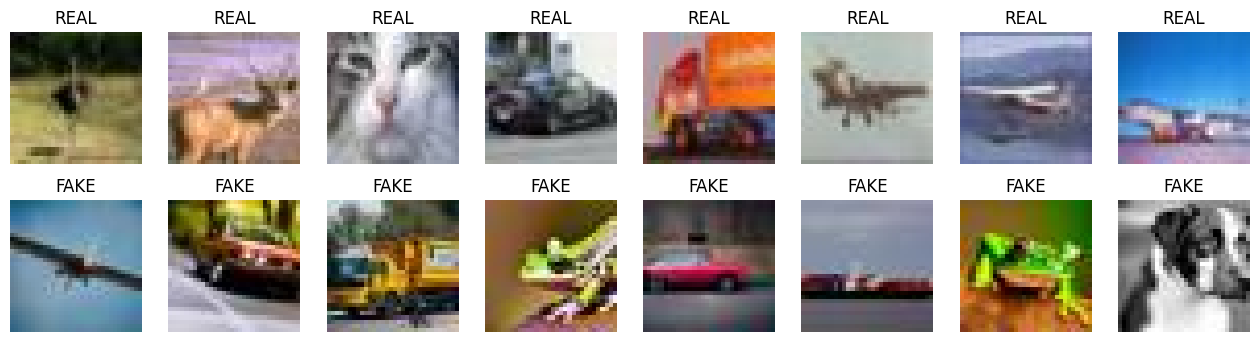

In [2]:
real_idx = np.where(y_train == 0)[0][10:18]   # 0 == real
fake_idx = np.where(y_train == 1)[0][10:18]   # 1 == fake

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(X_train[real_idx[i]].astype('uint8'))
    axes[0, i].set_title("REAL")
    axes[0, i].axis('off')

    axes[1, i].imshow(X_train[fake_idx[i]].astype('uint8'))
    axes[1, i].set_title("FAKE")
    axes[1, i].axis('off')

plt.show()

## Using pre trained model, with early stopping

In [3]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping

base = MobileNetV2(
    weights='imagenet', # loads kernels already learned from millions of ImageNet photots
    include_top=False,
    input_shape=(96, 96, 3) 
)

base.trainable = False

cnn = Sequential([
    layers.Input(shape=(X_train.shape[1:])),
    layers.Resizing(96,96),
    layers.Rescaling(1/127.5, offset = -1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(1, activation ='sigmoid')
])

cnn.summary()

cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy', #binary problem either Fake or Real
    metrics=['accuracy']
)

#sanity check for an untrained model
# cnn.evaluate(X_train, y_train)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience = 2,
    restore_best_weights=True
)

history = cnn.fit(
    X_train, y_train,
    epochs =10,
    batch_size = 64,
    validation_split = 0.1,
    callbacks=[early_stop]
)

cnn.evaluate(X_test, y_test)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 37s 224ms/step - accuracy: 0.7552 - loss: 0.4811 - val_accuracy: 0.8250 - val_loss: 0.3866
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 29s 202ms/step - accuracy: 0.8514 - loss: 0.3330 - val_accuracy: 0.8380 - val_loss: 0.3535
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 28s 195ms/step - accuracy: 0.8699 - loss: 0.2998 - val_accuracy: 0.8450 - val_loss: 0.3395
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 28s 198ms/step - accuracy: 0.8843 - loss: 0.2791 - val_accuracy: 0.8540 - val_loss: 0.3264
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 27s 192ms/step - accuracy: 0.8878 - loss: 0.2662 - val_accuracy: 0.8580 - val_loss: 0.3197
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.8921 - loss: 0.2556 - val_accuracy: 0.8580 - val_loss: 0.3246
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 28s 195ms/step - accuracy: 0.8972 - loss: 0.2504 - val_accuracy: 0.8670 - val_loss: 0.3134
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 28s 194ms/step - accuracy: 0.9007 - loss: 0

[0.29114705324172974, 0.8769999742507935]

## Metrics

Positive class = FAKE (label 1). REAL = 0.

- **True positive (TP):** a fake image correctly flagged as fake.
- **False negative (FN):** a fake image missed (predicted real).
- **False positive (FP):** a real photo wrongly flagged as fake.
- **True negative (TN):** a real photo correctly called real.

**Recall (FAKE) = TP / (TP + FN):** of all the images that really are fake,
the share the model caught. Low recall means fakes slip through.
Prioritise it when a missed fake is costly.

**Precision (FAKE) = TP / (TP + FP):** of all the images the model flagged
as fake, the share that really were fake. Low precision means many real
photos are wrongly flagged. Prioritise it when false alarms are costly
(for example, when flagged images are removed automatically).

**Trade-off:** raising the decision threshold above 0.5 gives higher
precision and lower recall. Lowering it does the opposite.

In [4]:
from sklearn.metrics import confusion_matrix, classification_report

probs = cnn.predict(X_test)
y_pred = (probs>0.5).astype(int).ravel()
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['Real', 'Fake']))

63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 164ms/step
[[885 122]
 [124 869]]
              precision    recall  f1-score   support

        Real       0.88      0.88      0.88      1007
        Fake       0.88      0.88      0.88       993

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000

